# 11. Modelo híbrido: Machine Learning + Deep Learning + reglas heurísticas

Este notebook combina cinco señales heterogéneas:

1. Random Forest sobre las 25 características.
2. MLP regularizada sobre las mismas características.
3. CNN 1D sobre los caracteres de la URL.
4. GRU sobre los caracteres de la URL.
5. Motor de reglas heurísticas auditable.

La fusión se aprende mediante una regresión logística sobre el conjunto de calibración.
El metaclasificador nunca utiliza el conjunto de prueba durante su entrenamiento. BiLSTM
permanece disponible como modelo independiente, pero se excluye inicialmente de la fusión
por su menor F1 y alta redundancia con GRU.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import hashlib
import json
import random
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import quote

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import Image, display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from heuristic_engine import analyze_url_heuristics

CLEAN_DATASET_PATH = Path("dataset-phishing-clean.csv")
TOP25_DATASET_PATH = Path("dataset-phishing-final-top25.csv")
SEQUENTIAL_DIR = Path("models/sequential")
OUTPUT_DIR = Path("models/hybrid")
PLOT_DIR = OUTPUT_DIR / "plots"
RANDOM_STATE = 42
BATCH_SIZE = 128
MAX_EPOCHS = 60
BRANCH_NAMES = ["random_forest", "mlp_regularized", "cnn_1d", "gru", "heuristic"]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Datos y particiones heredadas

In [2]:
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

clean = pd.read_csv(CLEAN_DATASET_PATH).dropna(subset=["url", "status"]).reset_index(drop=True)
top25 = pd.read_csv(TOP25_DATASET_PATH).reset_index(drop=True)
assert len(clean) == len(top25)
assert np.array_equal(clean["status"].astype(int).to_numpy(), top25["status"].astype(int).to_numpy())

def normalize_url_sequence(value):
    return quote(str(value).strip(), safe=":/?#[]@!$&'()*+,;=%-._~")

urls = clean["url"].map(normalize_url_sequence).to_numpy(dtype=str)
y = clean["status"].astype("int32").to_numpy()
feature_names = [column for column in top25.columns if column != "status"]
X = top25[feature_names].astype("float32")
assert len(feature_names) == 25

indices_file = np.load(SEQUENTIAL_DIR / "split_indices.npz")
split_indices = {name: indices_file[name] for name in ("train", "validation", "calibration", "test")}
train_idx = split_indices["train"]
validation_idx = split_indices["validation"]
calibration_idx = split_indices["calibration"]
test_idx = split_indices["test"]
display(pd.DataFrame({"partición": list(split_indices), "muestras": [len(value) for value in split_indices.values()]}))

,partición,muestras
0,train,6857
1,validation,1143
2,calibration,1143
3,test,2286


## 2. Ramas tabulares dedicadas al híbrido

In [3]:
random_forest = RandomForestClassifier(
    n_estimators=400,
    max_features="sqrt",
    min_samples_leaf=1,
    class_weight=None,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
random_forest.fit(X.iloc[np.concatenate([train_idx, validation_idx])], y[np.concatenate([train_idx, validation_idx])])

def build_hybrid_mlp():
    inputs = keras.Input(shape=(len(feature_names),), name="top25_features")
    x = layers.Dense(128, kernel_regularizer=regularizers.l2(1e-4))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(64, kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.25)(x)
    x = layers.Dense(32, activation="relu")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="phishing_probability")(x)
    model = keras.Model(inputs, outputs, name="hybrid_mlp_branch")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

hybrid_mlp = build_hybrid_mlp()
mlp_history = hybrid_mlp.fit(
    X.iloc[train_idx], y[train_idx],
    validation_data=(X.iloc[validation_idx], y[validation_idx]),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, min_delta=1e-4, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    ],
    verbose=2,
)
print("Random Forest y MLP entrenados sin usar calibración ni prueba")

Epoch 1/60
54/54 - 2s - 30ms/step - accuracy: 0.7966 - loss: 0.4643 - val_accuracy: 0.9169 - val_loss: 0.3206 - learning_rate: 0.0010
Epoch 2/60
54/54 - 0s - 3ms/step - accuracy: 0.9102 - loss: 0.2502 - val_accuracy: 0.9265 - val_loss: 0.2228 - learning_rate: 0.0010
Epoch 3/60
54/54 - 0s - 3ms/step - accuracy: 0.9237 - loss: 0.2203 - val_accuracy: 0.9300 - val_loss: 0.1973 - learning_rate: 0.0010
Epoch 4/60
54/54 - 0s - 3ms/step - accuracy: 0.9262 - loss: 0.2089 - val_accuracy: 0.9370 - val_loss: 0.1829 - learning_rate: 0.0010
Epoch 5/60
54/54 - 0s - 3ms/step - accuracy: 0.9278 - loss: 0.2038 - val_accuracy: 0.9396 - val_loss: 0.1758 - learning_rate: 0.0010
Epoch 6/60
54/54 - 0s - 3ms/step - accuracy: 0.9341 - loss: 0.1919 - val_accuracy: 0.9414 - val_loss: 0.1720 - learning_rate: 0.0010
Epoch 7/60
54/54 - 0s - 3ms/step - accuracy: 0.9339 - loss: 0.1903 - val_accuracy: 0.9423 - val_loss: 0.1710 - learning_rate: 0.0010
Epoch 8/60
54/54 - 0s - 3ms/step - accuracy: 0.9366 - loss: 0.1854 -

## 3. Ramas secuenciales y heurísticas

In [4]:
cnn_model = keras.models.load_model(SEQUENTIAL_DIR / "cnn_1d.keras")
gru_model = keras.models.load_model(SEQUENTIAL_DIR / "gru.keras")

def sequence_dataset(values):
    return tf.data.Dataset.from_tensor_slices(values).batch(128).prefetch(tf.data.AUTOTUNE)

heuristic_cache = [analyze_url_heuristics(value) for value in clean["url"].astype(str)]
heuristic_probabilities = np.array([result.probability for result in heuristic_cache], dtype="float64")
heuristic_rule_counts = np.array([len(result.rules) for result in heuristic_cache], dtype="int32")
print("Reglas activadas, promedio:", round(float(heuristic_rule_counts.mean()), 2))

Reglas activadas, promedio: 1.03


## 4. Matrices de señales para calibración y prueba

In [5]:
def branch_probabilities(indices):
    frame = X.iloc[indices]
    url_values = urls[indices]
    return pd.DataFrame({
        "random_forest": random_forest.predict_proba(frame)[:, 1],
        "mlp_regularized": hybrid_mlp.predict(frame, batch_size=256, verbose=0).reshape(-1),
        "cnn_1d": cnn_model.predict(sequence_dataset(url_values), verbose=0).reshape(-1),
        "gru": gru_model.predict(sequence_dataset(url_values), verbose=0).reshape(-1),
        "heuristic": heuristic_probabilities[indices],
    })

calibration_signals = branch_probabilities(calibration_idx)
test_signals = branch_probabilities(test_idx)
assert list(calibration_signals.columns) == BRANCH_NAMES
display(calibration_signals.describe().round(4))
display(calibration_signals.corr().round(3))

,random_forest,mlp_regularized,cnn_1d,gru,heuristic
count,1143.0000,1143.0000,1143.0000,1143.0000,1143.0000
mean,0.5119,0.5047,0.4917,0.4868,0.2117
std,0.4330,0.4621,0.4124,0.3586,0.1473
min,0.0000,0.0000,0.0160,0.0323,0.1266
25%,0.0325,0.0100,0.0663,0.0926,0.1266
50%,0.5400,0.6383,0.3925,0.4861,0.1558
75%,0.9750,0.9913,0.9738,0.8529,0.2242
max,1.0000,1.0000,1.0000,0.9981,0.9739


,random_forest,mlp_regularized,cnn_1d,gru,heuristic
random_forest,1.000,0.976,0.823,0.758,0.464
mlp_regularized,0.976,1.000,0.822,0.759,0.462
cnn_1d,0.823,0.822,1.000,0.851,0.506
gru,0.758,0.759,0.851,1.000,0.524
heuristic,0.464,0.462,0.506,0.524,1.000


## 5. Metaclasificador de fusión

In [6]:
meta_classifier = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
meta_classifier.fit(calibration_signals, y[calibration_idx])
hybrid_probabilities = meta_classifier.predict_proba(test_signals)[:, 1]
hybrid_threshold = 0.5
hybrid_predictions = (hybrid_probabilities >= hybrid_threshold).astype("int32")

coefficient_table = pd.DataFrame({
    "rama": BRANCH_NAMES,
    "coeficiente": meta_classifier.coef_[0],
    "odds_ratio": np.exp(meta_classifier.coef_[0]),
}).sort_values("coeficiente", ascending=False)
display(coefficient_table.round(4))

,rama,coeficiente,odds_ratio
0,random_forest,4.4901,89.1276
1,mlp_regularized,2.2978,9.9526
2,cnn_1d,2.0589,7.8373
3,gru,1.3840,3.9907
4,heuristic,0.4656,1.5930


## 6. Evaluación comparativa

In [7]:
def best_threshold(labels, probabilities):
    candidates = np.linspace(0.15, 0.85, 141)
    scores = [f1_score(labels, probabilities >= threshold) for threshold in candidates]
    return float(candidates[int(np.argmax(scores))])

validation_heuristic_threshold = best_threshold(y[validation_idx], heuristic_probabilities[validation_idx])
sequential_registry = json.loads((SEQUENTIAL_DIR / "sequential_registry.json").read_text(encoding="utf-8"))
sequential_thresholds = {item["id"]: item["threshold"] for item in sequential_registry["models"]}

test_probabilities = {
    "random_forest": test_signals["random_forest"].to_numpy(),
    "mlp_regularized": test_signals["mlp_regularized"].to_numpy(),
    "cnn_1d": test_signals["cnn_1d"].to_numpy(),
    "gru": test_signals["gru"].to_numpy(),
    "heuristic": test_signals["heuristic"].to_numpy(),
    "hybrid_ensemble": hybrid_probabilities,
}
thresholds = {
    "random_forest": 0.5,
    "mlp_regularized": 0.5,
    "cnn_1d": sequential_thresholds["cnn_1d"],
    "gru": sequential_thresholds["gru"],
    "heuristic": validation_heuristic_threshold,
    "hybrid_ensemble": hybrid_threshold,
}
display_names = {
    "random_forest": "Random Forest híbrido",
    "mlp_regularized": "MLP regularizada híbrida",
    "cnn_1d": "CNN 1D",
    "gru": "GRU",
    "heuristic": "Motor heurístico",
    "hybrid_ensemble": "LinkShield Hybrid Ensemble",
}

evaluation_rows = []
matrices = {}
for model_id, probabilities in test_probabilities.items():
    predictions = (probabilities >= thresholds[model_id]).astype("int32")
    tn, fp, fn, tp = confusion_matrix(y[test_idx], predictions, labels=[0, 1]).ravel()
    matrices[model_id] = np.array([[tn, fp], [fn, tp]])
    evaluation_rows.append({
        "model_id": model_id, "modelo": display_names[model_id], "threshold": thresholds[model_id],
        "accuracy": accuracy_score(y[test_idx], predictions),
        "precision": precision_score(y[test_idx], predictions),
        "recall": recall_score(y[test_idx], predictions),
        "f1": f1_score(y[test_idx], predictions),
        "roc_auc": roc_auc_score(y[test_idx], probabilities),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    })

results_df = pd.DataFrame(evaluation_rows).sort_values("f1", ascending=False).reset_index(drop=True)
metric_columns = ["threshold", "accuracy", "precision", "recall", "f1", "roc_auc"]
display(results_df.assign(**{column: results_df[column].round(4) for column in metric_columns}))
print("\nClasificación del ensamble híbrido")
print(classification_report(y[test_idx], hybrid_predictions, target_names=["Legítima", "Phishing"]))


Clasificación del ensamble híbrido
              precision    recall  f1-score   support

    Legítima       0.95      0.95      0.95      1143
    Phishing       0.95      0.95      0.95      1143

    accuracy                           0.95      2286
   macro avg       0.95      0.95      0.95      2286
weighted avg       0.95      0.95      0.95      2286



,model_id,modelo,threshold,accuracy,precision,recall,f1,roc_auc,tn,fp,fn,tp
0,hybrid_ensemble,LinkShield Hybrid Ensemble,0.500,0.9501,0.9525,0.9475,0.9500,0.9877,1089,54,60,1083
1,random_forest,Random Forest híbrido,0.500,0.9488,0.9422,0.9563,0.9492,0.9857,1076,67,50,1093
2,mlp_regularized,MLP regularizada híbrida,0.500,0.9405,0.9444,0.9361,0.9402,0.9813,1080,63,73,1070
3,cnn_1d,CNN 1D,0.250,0.8605,0.8275,0.9108,0.8671,0.9441,926,217,102,1041
4,gru,GRU,0.405,0.8355,0.8027,0.8898,0.8440,0.9170,893,250,126,1017
5,heuristic,Motor heurístico,0.150,0.6374,0.5962,0.8513,0.7013,0.7609,484,659,170,973


## 7. Matriz de confusión y comparación

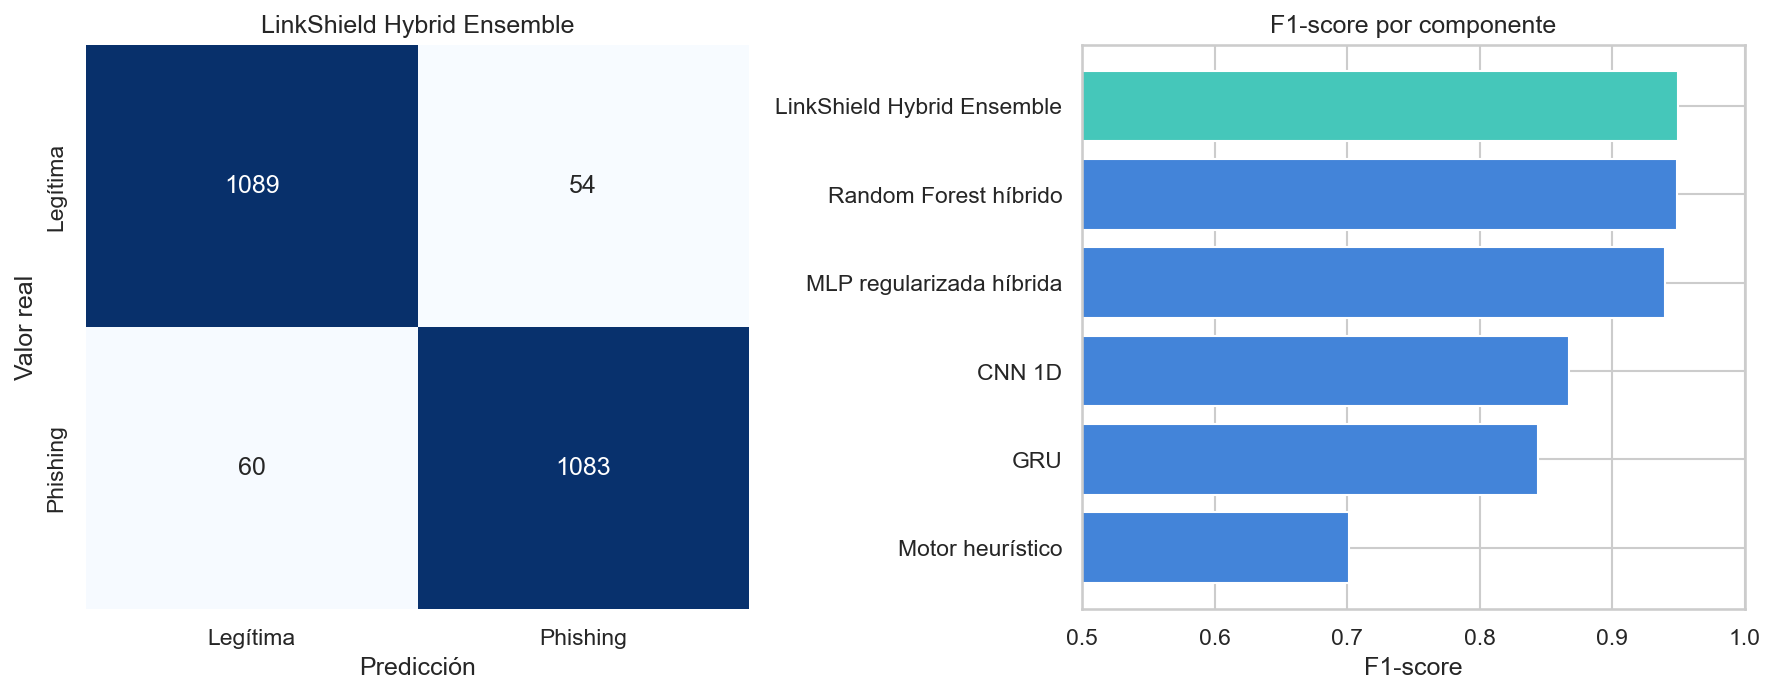

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(matrices["hybrid_ensemble"], annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Legítima", "Phishing"], yticklabels=["Legítima", "Phishing"], ax=axes[0])
axes[0].set_title("LinkShield Hybrid Ensemble")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Valor real")
ordered = results_df.sort_values("f1")
axes[1].barh(ordered["modelo"], ordered["f1"], color=["#45c7ba" if item == "hybrid_ensemble" else "#4384d9" for item in ordered["model_id"]])
axes[1].set_xlim(0.5, 1.0)
axes[1].set_title("F1-score por componente")
axes[1].set_xlabel("F1-score")
plt.tight_layout()
plot_path = PLOT_DIR / "evaluacion_hibrida.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(plot_path)))

## 8. Exportación del sistema híbrido

In [9]:
def artifact_id(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()[:12]

rf_path = OUTPUT_DIR / "hybrid_random_forest_branch.pkl"
mlp_path = OUTPUT_DIR / "hybrid_mlp_branch.keras"
meta_path = OUTPUT_DIR / "hybrid_meta_classifier.pkl"
joblib.dump(random_forest, rf_path)
hybrid_mlp.save(mlp_path)
joblib.dump(meta_classifier, meta_path)
joblib.dump(feature_names, OUTPUT_DIR / "hybrid_feature_names.pkl")
results_df.to_csv(OUTPUT_DIR / "metricas_modelo_hibrido.csv", index=False)

hybrid_row = next(row for row in results_df.to_dict("records") if row["model_id"] == "hybrid_ensemble")
rf_reference_f1 = 0.9491525423728814
recommended = float(hybrid_row["f1"]) > rf_reference_f1
exported_at = datetime.now(timezone.utc).isoformat()
registry = {
    "schema_version": 1,
    "exported_at": exported_at,
    "id": "hybrid_ensemble",
    "display_name": "LinkShield Hybrid Ensemble",
    "family": "hybrid",
    "runtime_type": "hybrid",
    "recommended": recommended,
    "threshold": hybrid_threshold,
    "dataset": {"name": CLEAN_DATASET_PATH.name, "total_rows": len(clean),
                **{f"{name}_rows": len(indices) for name, indices in split_indices.items()}},
    "branches": BRANCH_NAMES,
    "artifacts": {
        "random_forest": rf_path.name,
        "mlp_regularized": mlp_path.name,
        "meta_classifier": meta_path.name,
        "cnn_1d": "../sequential/cnn_1d.keras",
        "gru": "../sequential/gru.keras",
    },
    "artifact_ids": {"random_forest": artifact_id(rf_path), "mlp_regularized": artifact_id(mlp_path), "meta_classifier": artifact_id(meta_path)},
    "metrics": {key: float(hybrid_row[key]) for key in ("accuracy", "precision", "recall", "f1", "roc_auc")},
    "confusion_matrix": {key: int(hybrid_row[key]) for key in ("tn", "fp", "fn", "tp")},
    "meta_coefficients": {name: float(value) for name, value in zip(BRANCH_NAMES, meta_classifier.coef_[0])},
    "meta_intercept": float(meta_classifier.intercept_[0]),
    "heuristic_threshold": validation_heuristic_threshold,
    "random_forest_reference_f1": rf_reference_f1,
}
(OUTPUT_DIR / "hybrid_registry.json").write_text(json.dumps(registry, ensure_ascii=False, indent=2), encoding="utf-8")
print("Híbrido exportado. Recomendado:", recommended)

Híbrido exportado. Recomendado: True


## 9. Verificación de recarga

In [10]:
loaded_rf = joblib.load(OUTPUT_DIR / "hybrid_random_forest_branch.pkl")
loaded_mlp = keras.models.load_model(OUTPUT_DIR / "hybrid_mlp_branch.keras")
loaded_meta = joblib.load(OUTPUT_DIR / "hybrid_meta_classifier.pkl")
sample_idx = test_idx[:3]
sample_signals = pd.DataFrame({
    "random_forest": loaded_rf.predict_proba(X.iloc[sample_idx])[:, 1],
    "mlp_regularized": loaded_mlp.predict(X.iloc[sample_idx], verbose=0).reshape(-1),
    "cnn_1d": cnn_model.predict(sequence_dataset(urls[sample_idx]), verbose=0).reshape(-1),
    "gru": gru_model.predict(sequence_dataset(urls[sample_idx]), verbose=0).reshape(-1),
    "heuristic": heuristic_probabilities[sample_idx],
})
sample_hybrid = loaded_meta.predict_proba(sample_signals)[:, 1]
assert np.isfinite(sample_hybrid).all() and sample_hybrid.shape == (3,)
print("Probabilidades híbridas de prueba:", np.round(sample_hybrid, 6).tolist())

Probabilidades híbridas de prueba: [0.994493, 0.008143, 0.04033]


## Conclusión

El ensamble queda exportado como una alternativa adicional. Su recomendación general se
determina únicamente por comparación con el F1 histórico del Random Forest actual. Cada
rama conserva además su funcionamiento independiente para fines operativos y académicos.